# CPDS in Python Lab - Real Dataset Analysis with Pandas, NumPy and Matplotlib

## UCI Air Quality Dataset

**Dataset:** UCI Machine Learning Repository - Air Quality  
https://archive.ics.uci.edu/dataset/360/air%2Bquality

The UCI dataset contains hourly averaged measurements from an air-quality multisensor device deployed in an Italian city. The measurements were collected from March 2004 to February 2005.

> In the original dataset, the value `-200` represents a missing observation.

# Obtain the real dataset

### Question 1

Import:

- Pandas as `pd`,
- NumPy as `np`,
- Matplotlib `pyplot` as `plt`.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Question 2

Download the official UCI Air Quality ZIP file and extract `AirQualityUCI.csv`.

Then read the CSV file into a DataFrame called `df`.

The original CSV uses:

- `;` as the separator,
- `,` as the decimal symbol.

In [ ]:
df = pd.read_csv("AirQualityUCI.csv",sep=";",decimal=",")

df

FileNotFoundError: [Errno 2] No such file or directory: 'AirQualityUCI.csv'

## next cleaning

### Question 3

Remove completely empty columns and completely empty rows.

Then display the first five rows.

In [ ]:
df.dropna()

In [ ]:
df = df.dropna(axis=1,how="all")
df = df.dropna(axis=0,how="all")
df.head()

# Inspection of the dataset

### Question 4

Display:

1. the shape of the DataFrame,
2. the total number of elements,
3. the column names,
4. the index,
5. the data types.

In [ ]:
df.shape

In [ ]:
df.size

In [ ]:
df.columns.to_list()

In [ ]:
df.index

In [ ]:
df.dtypes

### Question 5

Display:

1. the first 5 rows,
2. the last 5 rows,
3. information about the dataset using `info()`.

In [ ]:
df.head()

In [ ]:
print(df.head())

In [ ]:
display(df.head())

In [ ]:
df.info()

### Question 6

Display descriptive statistics for the numerical columns.

In [ ]:
df.describe()

# Real missing data

$$
\text{A numerical value stored in a file is not always a valid measurement.}
$$

UCI states that the value `-200` is used to represent missing observations.

### Question 7

For each column, count how many entries are equal to `-200`.

Which variables contain the largest number of such values?

In [ ]:
(df==-200).sum()

### Question 8

Convert every `-200` entry into NumPy's missing-value representation `np.nan`.

Then count the missing values in every column.

In [ ]:
df[df==-200]=np.nan

In [ ]:
df.iloc[(df==-200).to_numpy()]

In [ ]:
df.isnull().sum()

### Question 9

Create a smaller DataFrame called `air` containing only:

- `Date`
- `Time`
- `CO(GT)`
- `C6H6(GT)`
- `NOx(GT)`
- `NO2(GT)`
- `T`
- `RH`
- `AH`

Display its first five rows.

In [ ]:
df.columns

In [ ]:
air = df[
    ['Date', 'Time', 'CO(GT)',
     'C6H6(GT)', 'NOx(GT)', 'NO2(GT)' ,'T', 'RH',
     'AH']]

In [ ]:
air.head()

### Question 10

Find the number of missing observations in each column of `air`.

Also find the percentage of missing values in each column.

$$
	\text{percentage missing}
=
\frac{	\text{number missing}}{	\text{number of rows}}	\times 100
$$

In [ ]:
air

In [ ]:
(air.isnull().sum()/air.shape[0])*100

### Question 11

Create a copy called `air_filled`.

In this copy:

- replace missing Temperature `T` values by the mean Temperature,
- replace missing Relative Humidity `RH` values by the mean Relative Humidity.

Check that those two columns no longer contain missing values.

In [ ]:
air_filled = air.copy()

In [ ]:
air_filled["T"] = air_filled["T"].fillna(air_filled["T"].mean())
air_filled["RH"] = air_filled["RH"].fillna(air_filled["RH"].mean())

In [ ]:
air_filled['T'].isnull().sum()

In [ ]:
air_filled['RH'].isnull().sum()

# Selecting, filtering and sorting real measurements

### Question 12

Display only the columns:

- `Date`,
- `Time`,
- `CO(GT)`,
- `NO2(GT)`.

Show the first 10 rows.

In [ ]:
df[["Date","Time","CO(GT)", "NO2(GT)"]].head(10)

### Question 13

Find all observations for which

$$
NO_2 > 200.
$$

Display only:

- Date,
- Time,
- NO2(GT).

In [ ]:
df[df['NO2(GT)']>200][["Date","Time","NO2(GT)"]]

In [ ]:
df.loc[df['NO2(GT)']>200, ["Date", "Time", "NO2(GT)"]]

### Question 14

Find observations satisfying both

$$
CO > 5
$$

and

$$
NO_2 > 200.
$$

Display Date, Time, CO and NO₂.

In [ ]:
df.loc[(df['NO2(GT)']>200) & (df["CO(GT)"]>5), ["Date", "Time", "NO2(GT)"]]

### Question 15

Find observations satisfying either

$$
CO > 5
$$

or

$$
NO_2 > 200.
$$

How many observations satisfy this condition?

In [ ]:
df.loc[(df['NO2(GT)']>200) | (df["CO(GT)"]>5), ["Date", "Time", "NO2(GT)"]]

### Question 16

Sort the complete `air` DataFrame according to NO₂ concentration in descending order.

Display the 10 highest NO₂ observations.

In [ ]:
air.sort_values("NO2(GT)", ascending=False)

# Basic statistical questions

### Question 17

For `NO2(GT)`, find:

1. mean,
2. minimum,
3. maximum,
4. standard deviation,
5. number of non-missing observations.

In [ ]:
air["NO2(GT)"].mean(), air["NO2(GT)"].min(),air["NO2(GT)"].std()

NameError: name 'air' is not defined

In [ ]:
air.shape[0]-air["NO2(GT)"].isnull().sum()

NameError: name 'air' is not defined

### Question 18

Find the mean values of:

- CO,
- benzene,
- NOx,
- NO₂,
- temperature,
- relative humidity.

In [ ]:
air.columns

NameError: name 'air' is not defined

In [ ]:
air[['CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)', 'T', 'RH',
       'AH']].mean()

NameError: name 'air' is not defined

# `groupby()` with a real time-series dataset

Every day contains repeated measurements at different times we can group sensor measurements by **Time**.

### Question 19

Find the mean NO₂ concentration for every Time value.

Sort the result in descending order and display the five times with the highest mean NO₂.

In [ ]:
(air.groupby("Time")["NO2(GT)"].mean().sort_values(ascending=False)).head(10)

In [ ]:
air

NameError: name 'air' is not defined

### Question 20

Find the mean CO and mean NO₂ simultaneously for every Time value.

In [ ]:
air.groupby("Time")[["CO(GT)","NO2(GT)"]].mean()

NameError: name 'air' is not defined

### Question 21

Group the data by `Date`.

Find the average NO₂ concentration for each date.

Display the 10 dates having the highest average NO₂.

In [ ]:
# do by yourself

# Matplotlib for this real data

### Question 22

Plot the mean NO₂ concentration against Time.

Use:

- a line,
- markers,
- axis labels,
- a title,
- a grid.

In [ ]:
dataset = air.groupby("Time")["NO2(GT)"].mean()

In [ ]:
dataset

,NO2(GT)
Time,
00.00.00,103.321429
01.00.00,90.502994
02.00.00,75.436747
03.00.00,80.115385
04.00.00,58.620482
05.00.00,59.612613
06.00.00,71.742515
07.00.00,94.709581
08.00.00,121.268293


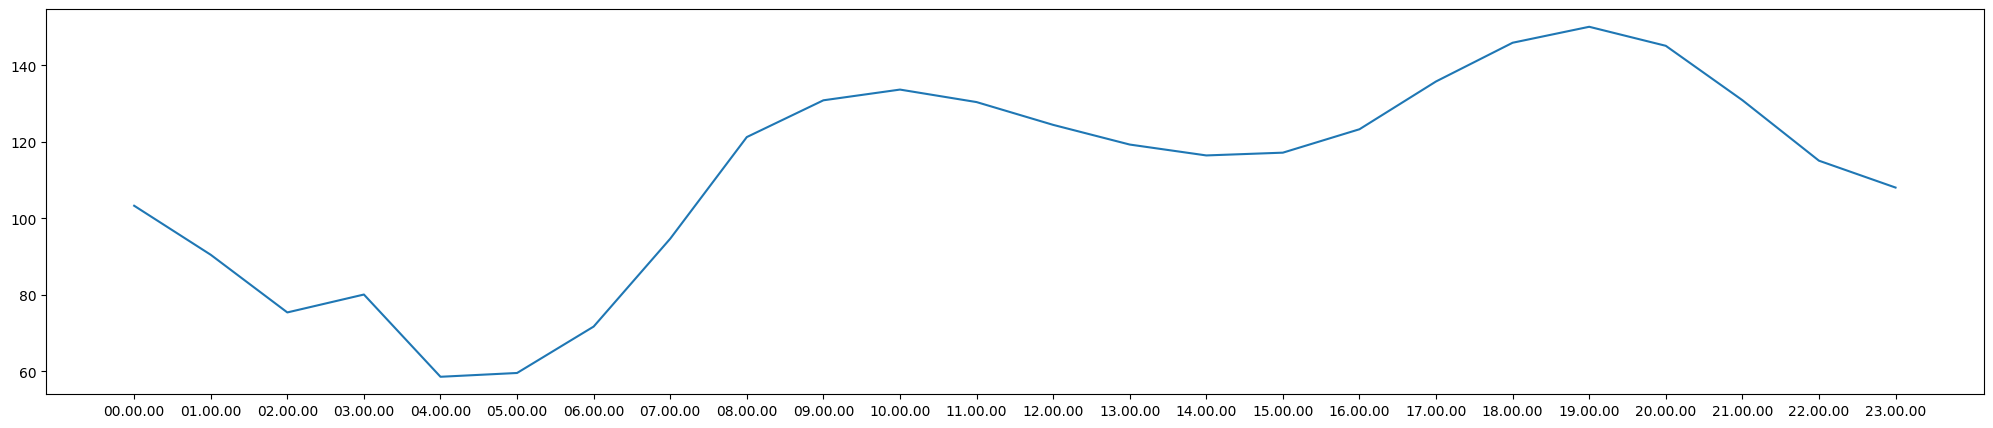

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(25,5))
plt.plot(dataset.index.to_list(), dataset.values)

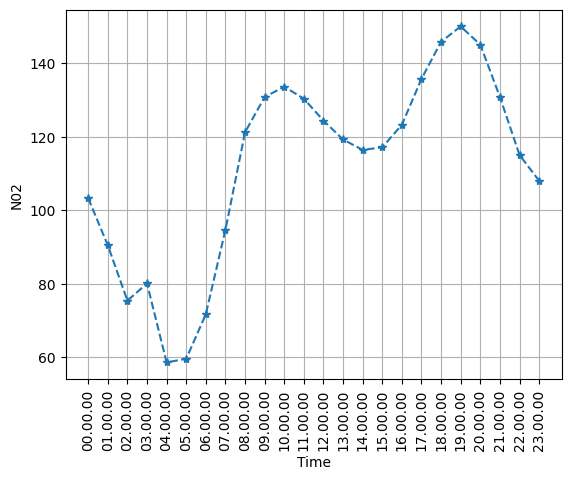

In [ ]:
plt.plot(dataset.index.to_list(), dataset.values, '--*')
plt.xticks(rotation=90)
plt.grid()
plt.xlabel("Time")
plt.ylabel("N02")
plt.show()

In [ ]:
max_val_dataset = dataset.max()

In [ ]:
max_time_dataset = ((dataset.sort_values(ascending=False)).index).to_list()[0]

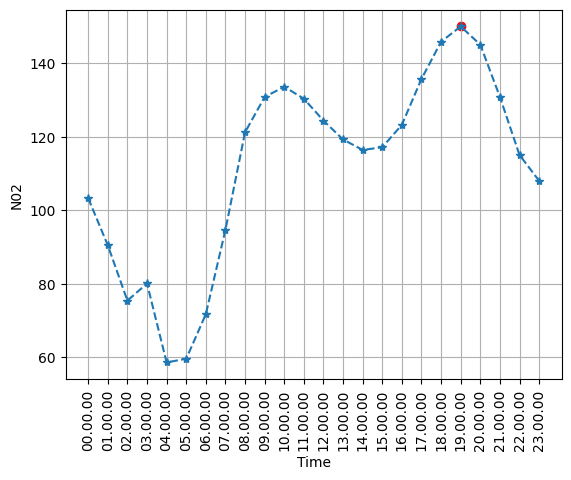

In [ ]:
plt.plot(dataset.index.to_list(), dataset.values, '--*')
plt.scatter(max_time_dataset, max_val_dataset,c="red")
plt.xticks(rotation=90)
plt.grid()
plt.xlabel("Time")
plt.ylabel("N02")
plt.show()

### Question 23

Find the maximum value of the hourly mean NO₂ concentration and the corresponding Time.

Then mark the maximum point separately on the graph.

### Question 24

Create a scatter plot of:

$$
	\text{Temperature}
\quad 	\text{vs} \quad
NO_2.
$$

In [ ]:
df.columns

Index(['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)',
       'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)',
       'PT08.S5(O3)', 'T', 'RH', 'AH'],
      dtype='object')

Text(0, 0.5, 'NO2')

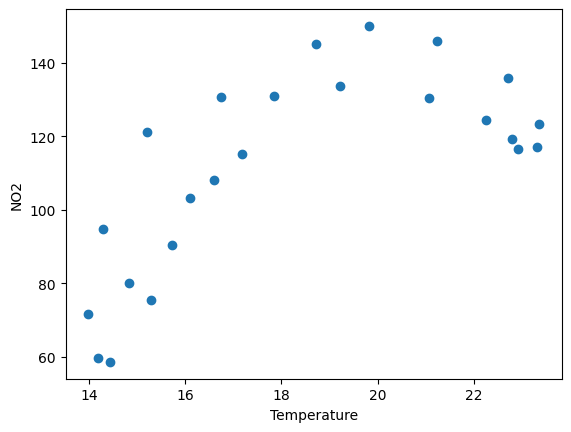

In [ ]:
plt.scatter(df.groupby("Time")["T"].mean(),
            df.groupby("Time")["NO2(GT)"].mean())
plt.xlabel("Temperature")
plt.ylabel("NO2")

### Question 25

Take the first 168 observations (approximately one week of hourly data).

Plot NO₂ concentration against observation number and draw a horizontal reference line at `200`.

In [ ]:
df.head(168)

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,17/03/2004,13.00.00,2.8,1452.0,188.0,15.1,1152.0,204.0,861.0,153.0,1747.0,1508.0,25.6,25.6,0.8254
164,17/03/2004,14.00.00,2.6,1389.0,152.0,13.7,1108.0,161.0,887.0,123.0,1712.0,1334.0,25.9,25.9,0.8503
165,17/03/2004,15.00.00,2.0,1207.0,103.0,10.4,994.0,135.0,1013.0,104.0,1520.0,1045.0,26.8,18.7,0.6500
166,17/03/2004,16.00.00,2.9,1365.0,193.0,15.2,1154.0,186.0,940.0,129.0,1679.0,1221.0,29.3,15.8,0.6309


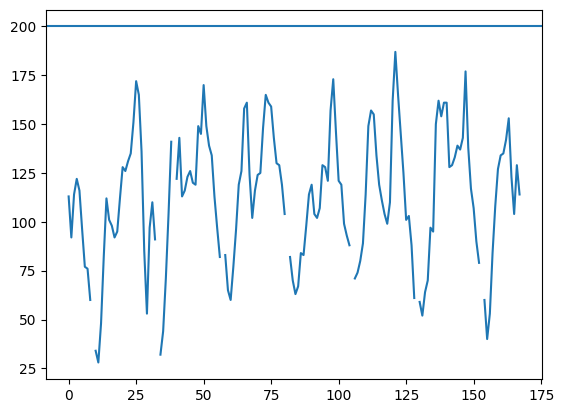

In [ ]:
plt.plot(df["NO2(GT)"][0:168])
plt.axhline(200)

# Pandas datas to NumPy

### Question 26

Use the following variables as input features:

$$
X =
[T,\ RH,\ AH,\ NOx]
$$

and use

$$
y = NO_2
$$

as the target.

First remove rows containing a missing value in any of these five variables.

Then create `X` and `y` as Pandas objects.

In [ ]:
df.columns

Index(['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)',
       'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)',
       'PT08.S5(O3)', 'T', 'RH', 'AH'],
      dtype='object')

In [ ]:
dataset = df[["T","RH","AH",'NOx(GT)',"NO2(GT)"]].dropna()
X = dataset[["T","RH","AH",'NOx(GT)']]
y = dataset["NO2(GT)"]

In [ ]:
display(X, y)

,T,RH,AH,NOx(GT)
0,13.6,48.9,0.7578,166.0
1,13.3,47.7,0.7255,103.0
2,11.9,54.0,0.7502,131.0
3,11.0,60.0,0.7867,172.0
4,11.2,59.6,0.7888,131.0
...,...,...,...,...
9352,21.9,29.3,0.7568,472.0
9353,24.3,23.7,0.7119,353.0
9354,26.9,18.3,0.6406,293.0
9355,28.3,13.5,0.5139,235.0


,NO2(GT)
0,113.0
1,92.0
2,114.0
3,122.0
4,116.0
...,...
9352,190.0
9353,179.0
9354,175.0
9355,156.0


### Question 27

Convert `X` and `y` into NumPy arrays.

Print:

- their types,
- their shapes.

In [ ]:
X = X.to_numpy()
X

array([[ 13.6   ,  48.9   ,   0.7578, 166.    ],
       [ 13.3   ,  47.7   ,   0.7255, 103.    ],
       [ 11.9   ,  54.    ,   0.7502, 131.    ],
       ...,
       [ 26.9   ,  18.3   ,   0.6406, 293.    ],
       [ 28.3   ,  13.5   ,   0.5139, 235.    ],
       [ 28.5   ,  13.1   ,   0.5028, 265.    ]])

In [ ]:
y = y.to_numpy()

In [ ]:
y

array([113.,  92., 114., ..., 175., 156., 168.])

# `merge()`

### Question 28

Create:

`pollution_df` containing

- Date,
- Time,
- CO(GT),
- NO2(GT),

and `weather_df` containing

- Date,
- Time,
- T,
- RH.

Use only the first 100 rows.

Merge the two DataFrames using both `Date` and `Time`.

# `concat()`

### Question 29

Create:

- `part1` containing rows 0 to 99,
- `part2` containing rows 100 to 199.

Concatenate the two parts vertically.

Check the shape of the resulting DataFrame.

# Save the cleaned dataset

### Question 30

Save `air` as

```text
AirQuality_Cleaned.csv
```

without writing the Pandas index to the file.

Then read the file back and display its first five rows.

In [ ]:
air

,Date,Time,CO(GT),C6H6(GT),NOx(GT),NO2(GT),T,RH,AH
0,10/03/2004,18.00.00,2.6,11.9,166.0,113.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,9.4,103.0,92.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,9.0,131.0,114.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,9.2,172.0,122.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,6.5,131.0,116.0,11.2,59.6,0.7888
...,...,...,...,...,...,...,...,...,...
9352,04/04/2005,10.00.00,3.1,13.5,472.0,190.0,21.9,29.3,0.7568
9353,04/04/2005,11.00.00,2.4,11.4,353.0,179.0,24.3,23.7,0.7119
9354,04/04/2005,12.00.00,2.4,12.4,293.0,175.0,26.9,18.3,0.6406
9355,04/04/2005,13.00.00,2.1,9.5,235.0,156.0,28.3,13.5,0.5139


In [ ]:
air.to_csv("AirQuality_Cleaned.csv")

# Linear Regression

We now use the cleaned UCI Air Quality data to study the relationship between:

- **input \(x\):** `NOx(GT)`
- **output \(y\):** `NO2(GT)`


We will do it in two ways:

1. **From scratch** using the least-squares formulas.
2. **Using NumPy** with `np.polyfit()`.

The fitted line has the form

$$
\hat y = b_0 + b_1 x,
$$

where

- $b_0$ is the intercept,
- $b_1$ is the slope,
- $\hat y$ is the value given by the fitted line.


In [ ]:
air.columns

Index(['Date', 'Time', 'CO(GT)', 'C6H6(GT)', 'NOx(GT)', 'NO2(GT)', 'T', 'RH',
       'AH'],
      dtype='object')

### Question 31

Create a new DataFrame called `reg_data` containing only

- `NOx(GT)`
- `NO2(GT)`

and remove rows containing missing values.

Display the first five rows and print the number of usable observations.


In [ ]:
reg_data = air[["NOx(GT)","NO2(GT)"]].dropna()
reg_data

,NOx(GT),NO2(GT)
0,166.0,113.0
1,103.0,92.0
2,131.0,114.0
3,172.0,122.0
4,131.0,116.0
...,...,...
9352,472.0,190.0
9353,353.0,179.0
9354,293.0,175.0
9355,235.0,156.0


### Question 32

Before fitting any line, create a scatter plot of

$$
x = NO_x
\qquad \text{and} \qquad
y = NO_2.
$$

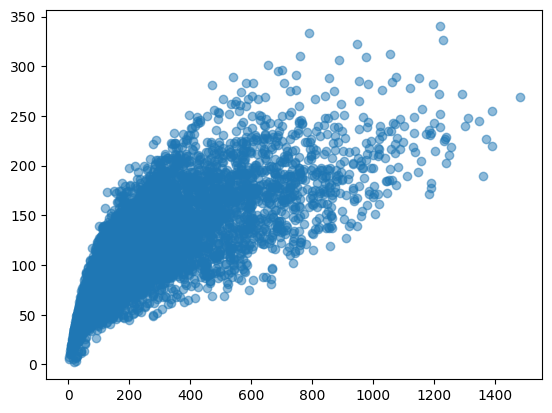

In [ ]:
x = reg_data["NOx(GT)"].to_numpy()
y = reg_data["NO2(GT)"].to_numpy()

plt.scatter(x,y,alpha=0.5)

# Linear regression from scratch

For observed points

$$
(x_1,y_1),(x_2,y_2),\ldots,(x_n,y_n),
$$

we want a line

$$
\hat y = b_0+b_1x
$$

that makes the vertical errors (residuals)

$$
e_i=y_i-\hat y_i
$$

as small as possible. The least-squares method chooses $b_0$ and $b_1$ to minimize

$$
\sum_{i=1}^{n}(y_i-\hat y_i)^2.
$$

For simple linear regression,

$$
b_1=
\frac{\sum (x_i-\bar{x})(y_i-\bar{y})}
{\sum (x_i-\bar{x})^2},
$$

and

$$
b_0=\bar{y}-b_1\bar{x}.
$$


### Question 33

Convert the two columns to NumPy arrays called `x` and `y`.

Then calculate

$$
\bar{x}
\quad\text{and}\quad
\bar{y}.
$$


In [ ]:
x_bar = np.mean(x)
y_bar = np.mean(y)

In [ ]:
x_bar, y_bar

(np.float64(246.93713545042127), np.float64(113.09125081011017))

### Question 34

Calculate the slope $b_1$ from scratch using

$$
b_1=
\frac{\sum (x_i-\bar{x})(y_i-\bar{y})}
{\sum (x_i-\bar{x})^2}.
$$


In [ ]:
b1 = np.sum((x-x_bar)*(y-y_bar))/np.sum((x-x_bar)**2)

### Question 35

Calculate the intercept

$$
b_0=\bar{y}-b_1\bar{x}.
$$

Then print the fitted linear-regression equation.


In [ ]:
b0 = y_bar - b1*x_bar

In [ ]:
b0, b1

(np.float64(70.3003999488094), np.float64(0.17328641471137532))

### Question 36

For every observed $x$-value, calculate the corresponding value on the fitted line:

$$
\hat y=b_0+b_1x.
$$

Store these values in `y_hat`.


In [ ]:
y_hat = b0 + b1*x

In [ ]:
y_hat

array([ 99.06594479,  88.14890066,  93.00092028, ..., 121.07331946,
       111.02270741, 116.22129985])

### Question 37

Draw the original scatter plot and place the regression line on the same figure.

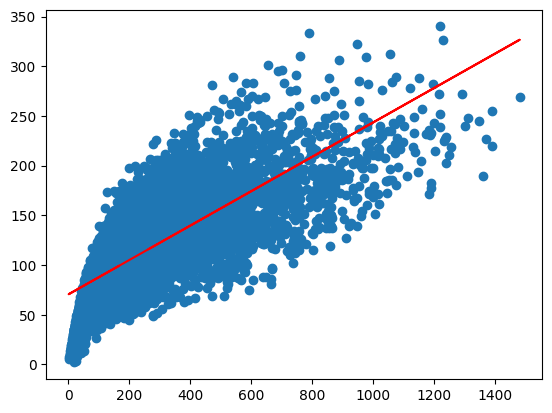

In [ ]:
plt.scatter(x,y)
plt.plot(x,y_hat, c = "red")

## What is a residual?

For each observation,

$$
\text{residual}
=
\text{observed value}
-
\text{fitted value}
=
y_i-\hat y_i.
$$

A point lying exactly on the regression line has residual \(0\).

A positive residual means the observed point lies above the line.  
A negative residual means it lies below the line.


### Question 38

Calculate the residuals and display the first ten.

Then calculate the sum of squared errors

$$
SSE=\sum (y_i-\hat y_i)^2.
$$


In [ ]:
SSE = np.sum((y-y_hat)**2)
SSE

np.float64(7538035.274062596)

### Question 39

Calculate the coefficient of determination (It is also called $R^2$-value-an important value in linear regression)

$$
R^2
=
1-
\frac{\sum (y_i-\hat y_i)^2}
{\sum (y_i-\bar y)^2}.
$$

Interpretation:

- $R^2$ near 1 means the straight line explains a large proportion of the variation in $y$.
- $R^2$ near 0 means the straight-line relationship explains little of the variation.


In [ ]:
R2 = 1- np.sum((y-y_hat)**2)/np.sum((y-y_bar)**2)

In [ ]:
R2

np.float64(0.582338522372956)

NumPy can calculate the coefficients of the best-fitting polynomial.

For a straight line we use degree \(1\):

```python
np.polyfit(x, y, 1)
```

It returns the slope and intercept.


### Question 40

Use `np.polyfit()` to calculate the regression line.

Compare its slope and intercept with the values obtained manually.


In [ ]:
np.polyfit(x,y,1)

array([ 0.17328641, 70.30039995])

### Question 41

Use the NumPy coefficients to draw the regression line again.

In [ ]:
x

array([166., 103., 131., ..., 293., 235., 265.])

In [ ]:
np.polyval(np.polyfit(x,y,1),x)

array([ 99.06594479,  88.14890066,  93.00092028, ..., 121.07331946,
       111.02270741, 116.22129985])

### Question 42

Take

$$
NO_x=200.
$$

Use the fitted line to calculate the corresponding model-based NO₂ value.

Then mark this point on the regression graph.


# Multiple Linear Regression

In simple linear regression, we used only one input variable:

$$
NO_x
$$

to predict

$$
NO_2.
$$

But in real problems, an output usually depends on several variables simultaneously.

We now use

$$
X=
[T,\ RH,\ AH,\ NO_x]
$$

to predict

$$
y=NO_2.
$$

Thus, instead of fitting a line of the form

$$
\hat y=b_0+b_1x,
$$

we fit a model of the form

$$
\hat y
=
b_0
+b_1x_1
+b_2x_2
+b_3x_3
+b_4x_4.
$$

For our air-quality data,

$$
\widehat{NO_2}
=
b_0
+b_1 T
+b_2 RH
+b_3 AH
+b_4 NO_x.
$$

Here:

- $b_0$ is the intercept,
- $b_1$ measures the contribution of Temperature,
- $b_2$ measures the contribution of Relative Humidity,
- $b_3$ measures the contribution of Absolute Humidity,
- $b_4$ measures the contribution of NOx.

### Question 43

Create a new DataFrame called `mlr_data` containing only

- `T`
- `RH`
- `AH`
- `NOx(GT)`
- `NO2(GT)`

Remove all rows containing missing values.

### Question 44

Separate the data into

$$
X=
[T,\ RH,\ AH,\ NO_x]
$$

and

$$
y=NO_2.
$$

Keep them as Pandas objects first.

Display the first five rows of $X$ and the first five values of $y$.

### Question 45

Convert `X` and `y` into NumPy arrays called

`X_np`

and

`y_np`

respectively.

Print their shapes.

# Multiple linear regression from scratch

For one observation, the model is

$$
\hat y_i
=
b_0
+b_1x_{i1}
+b_2x_{i2}
+b_3x_{i3}
+b_4x_{i4}.
$$

Instead of writing every equation separately, we can write all observations simultaneously using matrices. Define

$$
\mathbf{X}
=
\begin{bmatrix}
1 & x_{11} & x_{12} & x_{13} & x_{14}\\
1 & x_{21} & x_{22} & x_{23} & x_{24}\\
\vdots & \vdots & \vdots & \vdots & \vdots\\
1 & x_{n1} & x_{n2} & x_{n3} & x_{n4}
\end{bmatrix}
$$

and

$$
\boldsymbol{\beta}
=
\begin{bmatrix}
b_0\\
b_1\\
b_2\\
b_3\\
b_4
\end{bmatrix}.
$$

Then

$$
\hat{\mathbf y}
=
\mathbf X\boldsymbol{\beta}.
$$

The first column consists entirely of $1$'s because it corresponds to the intercept $b_0$.

### Question 46

Create the design matrix by adding a column of ones to `X_np`. Call the resulting matrix `X_design`. Display its first five rows and print its shape.

The first column now corresponds to the intercept. Therefore, the columns represent

$$
[1,\ T,\ RH,\ AH,\ NO_x].
$$

# Least-squares idea

As in simple linear regression, the residual for observation $i$ is

$$
e_i=y_i-\hat y_i.
$$

The least-squares method chooses the coefficients so that

$$
SSE
=
\sum_{i=1}^{n}(y_i-\hat y_i)^2
$$

is as small as possible. In matrix form,

$$
SSE
=
(\mathbf y-\mathbf X\boldsymbol{\beta})^T
(\mathbf y-\mathbf X\boldsymbol{\beta}).
$$

Minimizing this quantity gives the normal equations

$$
\mathbf X^T\mathbf X\boldsymbol{\beta}
=
\mathbf X^T\mathbf y.
$$

Hence,

$$
\boldsymbol{\beta}
=
(\mathbf X^T\mathbf X)^{-1}
\mathbf X^T\mathbf y.
$$

### Question 47

Calculate

$$
\mathbf X^T\mathbf X
$$

and

$$
\mathbf X^T\mathbf y.
$$

Print their shapes.

### Question 48

Use the normal-equation formula

$$
\boldsymbol{\beta}
=
(\mathbf X^T\mathbf X)^{-1}
\mathbf X^T\mathbf y
$$

to calculate the regression coefficients.

Store them in `beta`.

The entries of `beta` are

$$
[b_0,b_1,b_2,b_3,b_4].
$$

### Question 49

Separate the coefficients into

`b0, b1, b2, b3, b4`

and print the fitted multiple-linear-regression equation

$$
\widehat{NO_2}
=
b_0+b_1T+b_2RH+b_3AH+b_4NO_x.
$$

Suppose the fitted model is

$$
\widehat{NO_2}
=
b_0+b_1T+b_2RH+b_3AH+b_4NO_x.
$$

The interpretation of $b_1$ is different from simple linear regression.

It tells us the estimated change in $NO_2$ when $T$ increases by one unit while the other input variables are kept fixed.

Similarly, $b_4$ describes the estimated change associated with one unit increase in $NO_x$, while $T$, $RH$, and $AH$ are kept fixed.

### Question 50

Use the fitted coefficients to calculate the predicted NO₂ value for every observation.

Use

$$
\hat{\mathbf y}
=
\mathbf X\boldsymbol{\beta}.
$$

Store the result in `y_hat_mlr`.

### Question 51

Calculate the residuals

$$
e_i=y_i-\hat y_i.
$$

Display the first ten residuals.

Then calculate

$$
SSE
=
\sum_{i=1}^{n}(y_i-\hat y_i)^2.
$$

### Question 52

Calculate the coefficient of determination

$$
R^2
=
1-
\frac{
\sum(y_i-\hat y_i)^2
}{
\sum(y_i-\bar y)^2
}.
$$

Interpret the result.

The $R^2$-value measures the proportion of variation in NO₂ explained by the regression model. For example,

$$
R^2=0.80
$$

would mean that approximately $80\%$ of the variation in the observed NO₂ values is explained by the variables included in the model.

# Is multiple regression better than simple regression?

Previously we predicted NO₂ using only NOx. Now we are using

$$
T,\ RH,\ AH,\ NO_x.
$$

To make a fair comparison, both models must be fitted using exactly the same observations.

### Question 53

Using the same `mlr_data`, fit a simple linear regression using only

$$
NO_x
$$

to predict

$$
NO_2.
$$

Calculate its $R^2$-value and compare it with the multiple-regression $R^2$.

An important observation is that adding more variables can increase $R^2$. But this does not automatically mean that every added variable is useful.

# Actual values versus predicted values

A useful way to inspect a regression model is to compare

$$
y
$$

with

$$
\hat y.
$$

For a perfect prediction,

$$
y=\hat y.
$$

Therefore, all points would lie on the diagonal line

$$
y=x.
$$

### Question 54

Create a scatter plot with

- actual NO₂ values on the horizontal axis,
- predicted NO₂ values on the vertical axis.

Also draw the reference line

$$
y=x.
$$

# NumPy's built-in least-squares solver

Instead of explicitly calculating

$$
(\mathbf X^T\mathbf X)^{-1},
$$

NumPy can solve the least-squares problem directly using

```python
np.linalg.lstsq()
```

### Question 55

Use

```python
np.linalg.lstsq()
```

to calculate the regression coefficients.

# Multiple linear regression using a machine-learning library

The same model can be fitted directly using `LinearRegression` from `scikit-learn`.

### Question 56

Import `LinearRegression` from `sklearn.linear_model`.

Fit a multiple linear regression model using

$$
[T,\ RH,\ AH,\ NO_x]
$$

to predict

$$
NO_2.
$$

Print the intercept and coefficients.

The coefficients correspond to the columns

$$
[T,\ RH,\ AH,\ NO_x].
$$

### Question 57

Use the fitted `LinearRegression` model to predict NO₂ for all observations.

Then calculate its $R^2$-value using

```python
model.score(X, y)
```

and compare it with the $R^2$-value calculated manually.

# Making a prediction

Suppose atmospheric conditions are

$$
T=20,
\qquad
RH=50,
\qquad
AH=1,
\qquad
NO_x=200.
$$

The fitted regression model can be used to estimate the corresponding NO₂ concentration.

### Question 58

Use the multiple linear regression model to predict NO₂ when

$$
T=20,
\qquad
RH=50,
\qquad
AH=1,
\qquad
NO_x=200.
$$

First calculate the prediction manually from

$$
\widehat{NO_2}
=
b_0+b_1T+b_2RH+b_3AH+b_4NO_x.
$$

Then verify the answer using `model.predict()`.